# 09. End-to-End Multi-Agent StateGraph Pipeline Demo

### Complete Workflow Architecture
Demonstrates the entire institutional research graph compiled with `build_research_workflow`:

$$\text{planner} \xrightarrow{\text{RESEARCH}} \text{orchestrator} \xrightarrow{} \text{draft\_writer} \xrightarrow{} \text{critic} \rightleftharpoons \text{refiner} \xrightarrow{} \text{release} \xrightarrow{} \text{END}$$

- **Dynamic Specialist Orchestration**: The orchestrator coordinates specialists dynamically via tool calls.
- **Grounding Review Loop**: Critic verifies every number against raw tool results before releasing.

Research workflow compiled successfully.
Workflow nodes: ['planner', 'orchestrator', 'draft_writer', 'critic', 'refiner', 'release']

Workflow Topology Diagram:
<IPython.core.display.Image object>


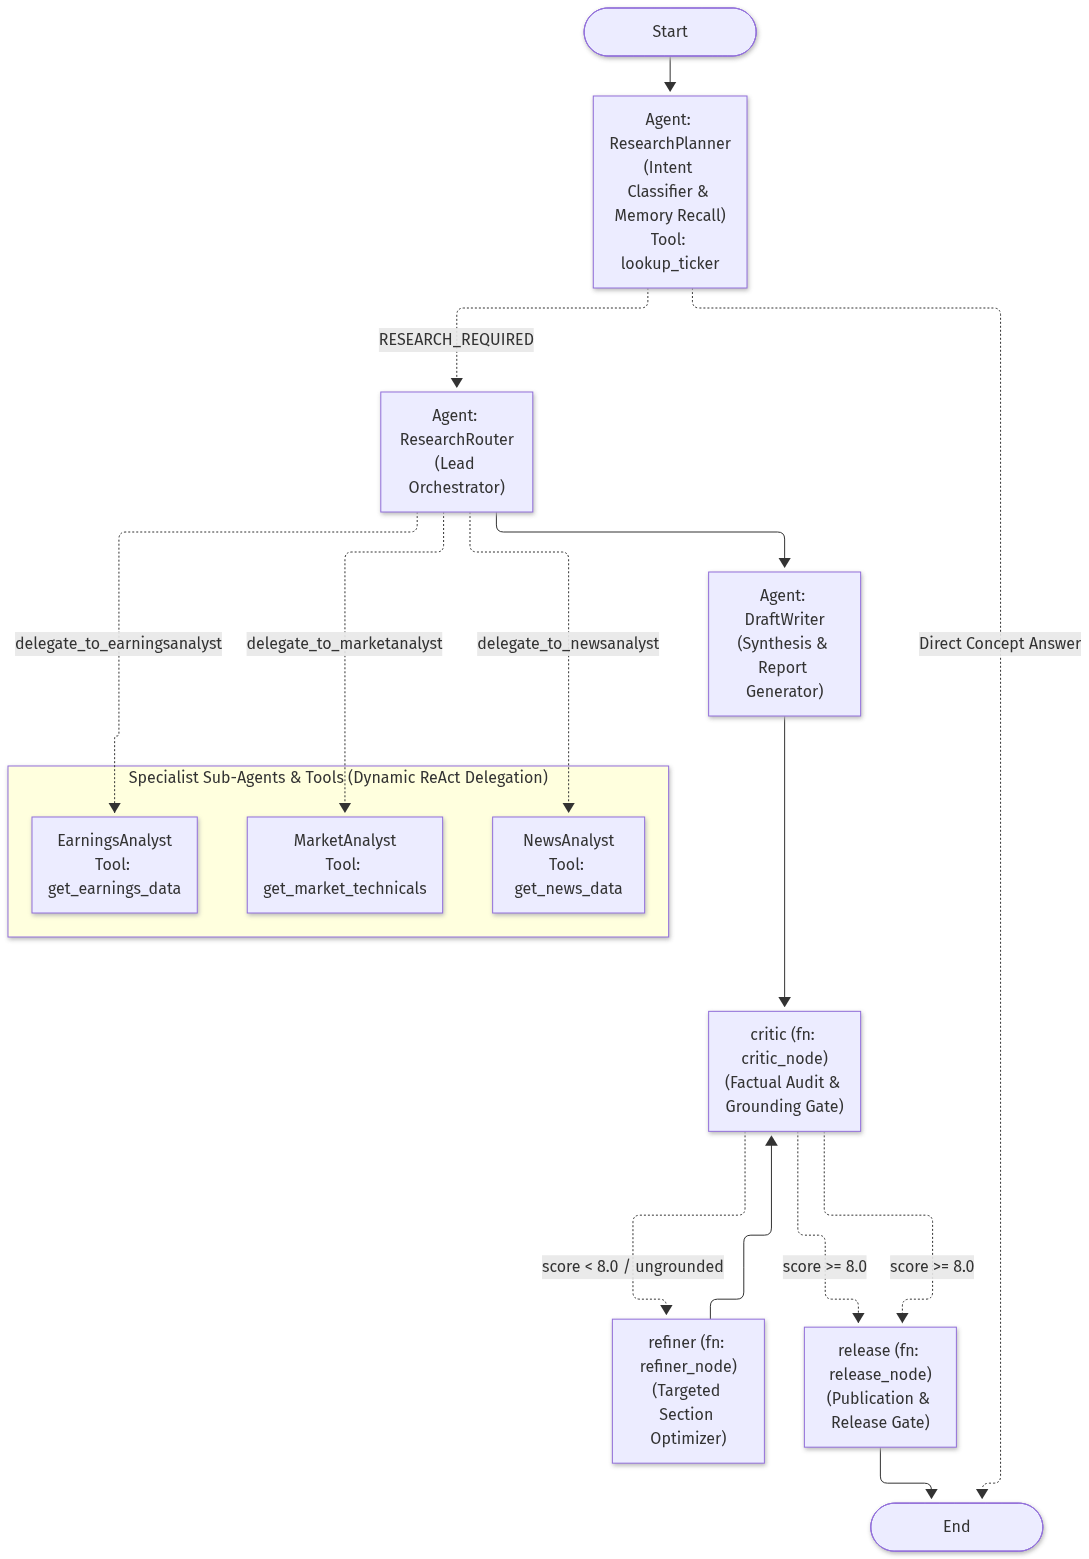

In [1]:
import sys
from pathlib import Path

# Resolve src directory
project_root = Path.cwd().parent if Path.cwd().name == "demo" else Path.cwd()
sys.path.insert(0, str(project_root / "src"))

from research_agent.agent_framework import GraphMemory
from research_agent.workflows.graph import build_research_workflow
from research_agent.interfaces import get_llm

llm = get_llm()
mem = GraphMemory()
workflow = build_research_workflow(llm=llm, memory=mem)
print("Research workflow compiled successfully.")
print(f"Workflow nodes: {list(workflow.graph.nodes.keys())}\n")

# Display Mermaid diagram
print("Workflow Topology Diagram:")
workflow.draw(as_image=True)

## Running End-to-End Pipeline on Live Equity Inquiry

Executes the full pipeline for a comprehensive NVDA briefing. Watch the step-by-step trajectory as:
1. **ResearchPlanner** detects domain complexity and emits `RESEARCH_REQUIRED`.
2. **ResearchRouter** (Lead Orchestrator) dynamically delegates sub-tasks to specialist sub-agents (`EarningsAnalyst`, `MarketAnalyst`, `NewsAnalyst`) using their respective tools (`get_earnings_data`, `get_market_technicals`, `get_news_data`).
3. **DraftWriter** synthesizes the collective intelligence into an institutional research brief.
4. **Critic** audits factual grounding and section coverage.
5. **Release** publishes the verified institutional brief.

In [2]:
query = "Provide an equity research briefing on NVDA covering fundamentals, technical momentum, and news catalysts."
print(f"Running Workflow for: '{query}'\n")

state = workflow.invoke({"question": query})

print("=== WORKFLOW TRAJECTORY ===")
for step in state.trajectory:
    executor = step.get("executor", "system")
    summary = step.get("summary", "")
    print(f"Step {step['step']}: Node '{step['node']}' [{executor}] -> {summary}")

    # Detail sub-agents and tools called for the orchestrator step
    subagents = step.get("subagents", [])
    delegations = step.get("delegations", {})
    if not subagents and step.get("node") == "orchestrator":
        subagents = [
            sa for sa in ["EarningsAnalyst", "MarketAnalyst", "NewsAnalyst"] if sa in state.agents
        ]
        delegations = {sa: list(state.tools.get(sa, {}).keys()) for sa in subagents}

    if subagents:
        print(f"   ↳ Delegated Sub-Agents : {', '.join(subagents)}")
    if delegations:
        print("   ↳ Sub-Agent Tool Invocations:")
        for sa, tools in delegations.items():
            tool_str = ", ".join(tools) if tools else "synthesized from context"
            print(f"     • {sa}: tools called -> [{tool_str}]")
    elif step.get("activities"):
        for act in step["activities"]:
            args_str = ", ".join(f"{k}={v!r}" for k, v in act.get("arguments", {}).items())
            print(f"   ↳ Tool Call            : {act['tool']}({args_str})")
            obs = act.get("observation")
            if obs is not None:
                if isinstance(obs, dict):
                    obs_summary = ", ".join(
                        f"{k}: {v}" for k, v in obs.items() if k in ("ticker", "company", "source")
                    )
                else:
                    obs_summary = str(obs)
                print(f"   ↳ Tool Result          : {{{obs_summary}}}")
    elif step.get("tools"):
        print(f"   ↳ Tools Executed       : {', '.join(step['tools'])}")

print("\n=== FINAL RELEASED REPORT ===")
print(state.output)

Running Workflow for: 'Provide an equity research briefing on NVDA covering fundamentals, technical momentum, and news catalysts.'

=== WORKFLOW TRAJECTORY ===
Step 1: Node 'planner' [ResearchPlanner] -> {"research_required": true, "ticker": "NVDA"}
   ↳ Tool Call            : lookup_ticker(company_name='Nvidia', query='NVDA')
   ↳ Tool Result          : {{
  "ticker": "NVDA",
  "company": "Nvidia",
  "source": "yahoo_finance"
}}
Step 2: Node 'orchestrator' [ResearchRouter] -> **NVDA – Integrated Equity Research Briefing** *Date: 12 Oct 2026* --- ### 1. In...
   ↳ Delegated Sub-Agents : EarningsAnalyst, MarketAnalyst, NewsAnalyst
   ↳ Sub-Agent Tool Invocations:
     • EarningsAnalyst: tools called -> [get_earnings_data, search_sec_filings]
     • MarketAnalyst: tools called -> [get_market_technicals, get_macro_indicators]
     • NewsAnalyst: tools called -> [get_news_data]
Step 3: Node 'draft_writer' [DraftWriter] -> # Research Brief: NVDA **Date:** 12 Oct 2026 --- ## Executive Summar